# 为什么 IoU 提高了，自动定位却变差？

这份 Notebook 用已有 CSV 和图片解释**事后挑选的失败样例**，不能用它们证明新算法泛化。生成数据的两个脚本是 `diagnose_event_quality_localization.py` 和 `run_event_quality_localizer_ablation.py`。

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

base = Path.cwd()
if not (base / 'event_quality_failure_diagnosis').exists():
    base = base / 'muon_analysis'
cases_dir = base / 'event_quality_failure_diagnosis'
ablation_dir = base / 'event_quality_localizer_ablation_results'
if not cases_dir.exists() or not ablation_dir.exists():
    raise FileNotFoundError('请先运行两份诊断与消融脚本')
cases = pd.read_csv(cases_dir / 'diagnostic_cases.csv')
cases[['scenario', 'event_count', 'repeat', 'position_sigma_mm',
       'method', 'iou', 'global_error_mm', 'auto_error_mm',
       'window_bins', 'window_start_x', 'window_start_y']].round(3)

,scenario,event_count,repeat,position_sigma_mm,method,iou,global_error_mm,auto_error_mm,window_bins,window_start_x,window_start_y
0,offcenter,5000,1,0.1,hard,0.384,15.351,17.544,18,13,2
1,offcenter,5000,1,0.1,majority,0.456,7.331,34.097,14,17,2
2,offcenter,5000,2,0.3,hard,0.207,31.832,33.870,14,9,1
3,offcenter,5000,2,0.3,majority,0.213,35.606,64.425,14,3,1
4,small,3000,4,0.3,hard,0.054,5.709,5.877,18,6,6
5,small,3000,4,0.3,majority,0.064,18.323,64.452,18,0,14


## 看偏心目标的一次窗口跳变

青色是真值轮廓与中心，仅用于事后诊断；绿色为算法自己选的窗口与定位点。比较左右两图：右图的 IoU 较高，但绿色窗口缩小并偏向 U 型一侧。

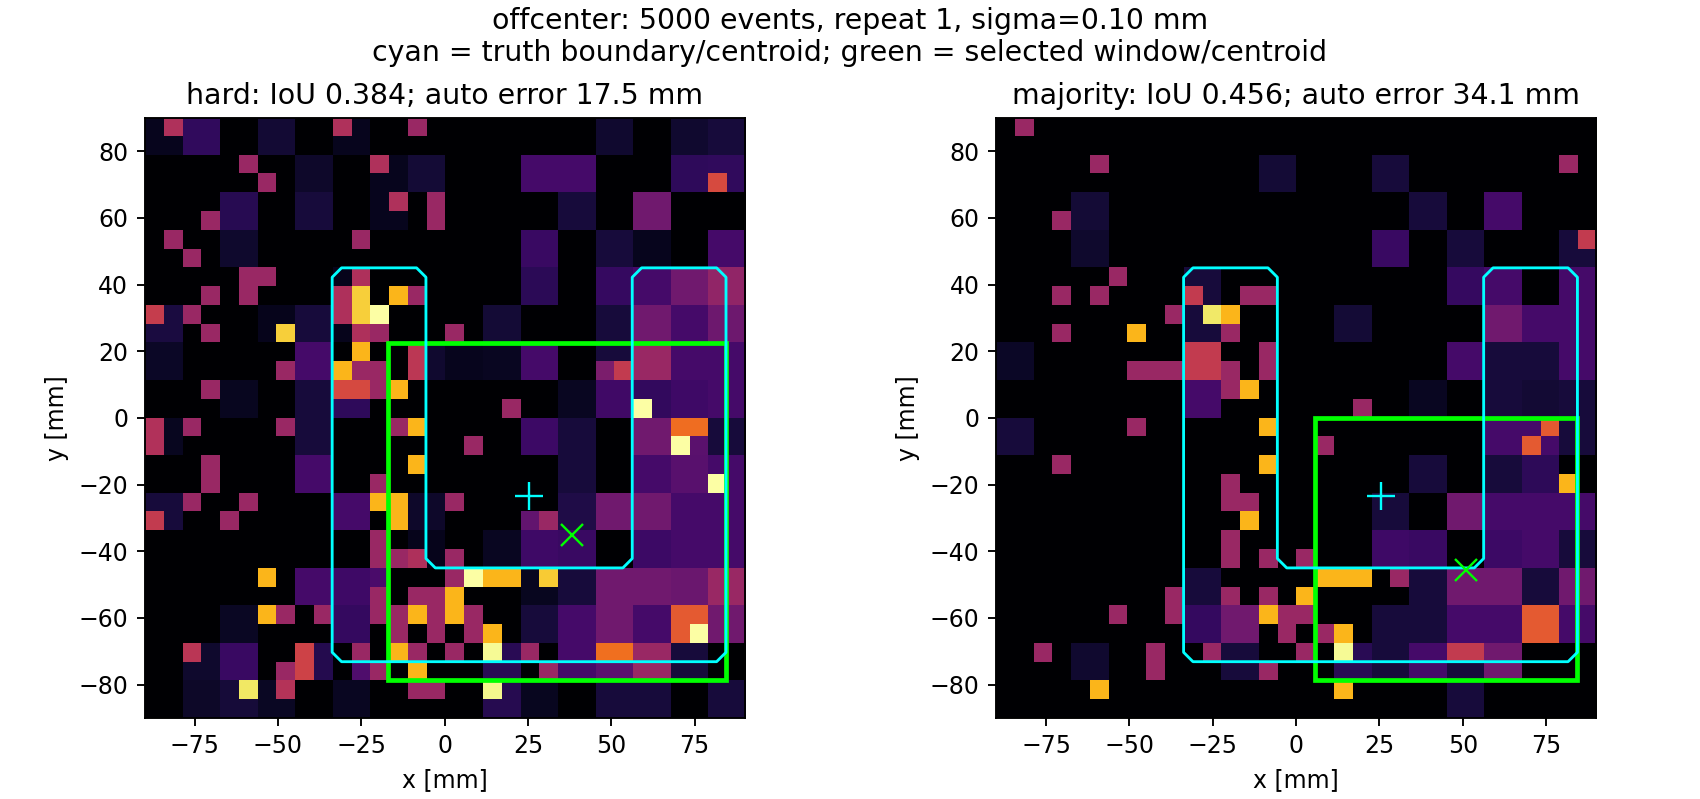

In [2]:
display(Image(filename=str(cases_dir / 'offcenter_5000_r1_sigma0.10.png')))

## 用全部条件检查定位器

下面只看非零位置误差。均值衡量总体水平，P90 衡量坏情况的长尾。固定24格是已有强对照，但使用了目标最大尺度的先验。

In [3]:
all_runs = pd.read_csv(ablation_dir / 'localizer_ablation_by_repeat.csv')
noisy = all_runs[all_runs['position_sigma_mm'] > 0]
columns = ['global_error_mm', 'fixed24_error_mm',
           'multiscale_error_mm', 'robust_multiscale_error_mm']
noisy.groupby('method')[columns].agg(['mean', lambda x: x.quantile(.9)]).round(2)

global_error_mm            fixed24_error_mm             \
                    mean <lambda_0>             mean <lambda_0>   
method                                                            
hard               13.34      28.37            14.40      31.82   
majority           12.94      28.87            13.86      33.20   

         multiscale_error_mm            robust_multiscale_error_mm             
                        mean <lambda_0>                       mean <lambda_0>  
method                                                                         
hard                   20.81      56.04                      20.87      53.89  
majority               20.84      56.94                      21.82      57.49

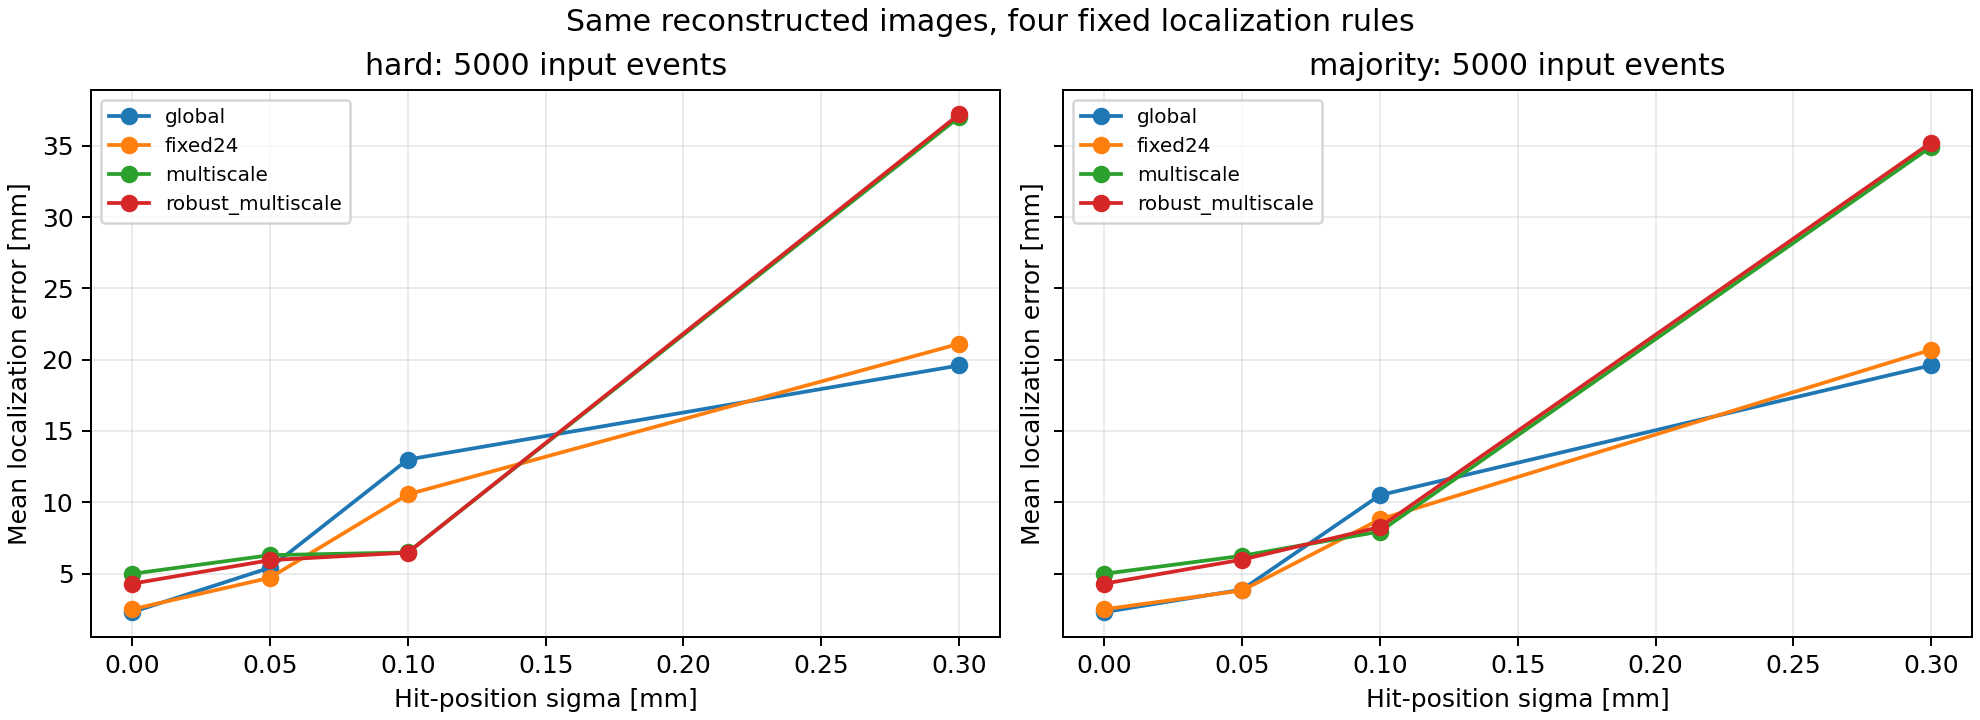

In [4]:
display(Image(filename=str(ablation_dir / 'localizer_ablation_5000.png')))